# How accurately a pose follows from its keypoints

The chapter derived how a pose is recovered from the pixels of known points of the target, and predicted how its error depends on the pixel error, the distance and the number of points. This notebook checks all of it on the geometry of SPEED+: the camera of the dataset, the eleven keypoints of Tango and the poses of its labels.

The pixels used here are not found in images. They are the exact projections of the keypoints with the labeled pose, to which a known error is added. This isolates the geometry from the recognition of the keypoints: whatever error appears here is the price of the geometry alone, and it tells how accurate a keypoint detector must be for the pose to meet the requirement of the problem chapter.

In [1]:
%matplotlib inline

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})

COL_A = "#1f77b4"
COL_B = "#d62728"
COL_C = "#9467bd"
COL_D = "#2ca02c"

# local copy of the dataset, filled on demand from the public archive
DATA = Path("../../data/speedplus")

import time

from ios_pose_estimation.camera import project_pose
from ios_pose_estimation.pnp import pose_errors, ransac_pnp, solve_pnp, speed_score
from ios_pose_estimation.rotations import quaternion_to_rotation_matrix
from ios_pose_estimation.speedplus import TANGO_KEYPOINTS, SpeedPlus

dataset = SpeedPlus(DATA)
camera = dataset.camera()
labels = dataset.labels("synthetic", "validation")
rng = np.random.default_rng(0)
sample = [labels[i] for i in rng.choice(len(labels), 600, replace=False)]
distance = np.array([label.distance for label in sample])


def keypoints(label):
    pixels, _ = project_pose(camera, label.quaternion, label.translation, TANGO_KEYPOINTS)
    return pixels


def errors(label, estimate):
    orientation, _, normalized = pose_errors(estimate.quaternion, estimate.translation, label.quaternion, label.translation)
    return np.degrees(orientation), normalized

## Exact keypoints give the exact pose

With the exact projections, the linear estimate followed by the refinement must return the labeled pose to the precision of the arithmetic. This is the first test of the whole chain, including the distortion of the lens and the convention of the poses.

In [2]:
started = time.perf_counter()
exact = np.array([errors(label, solve_pnp(camera, TANGO_KEYPOINTS, keypoints(label))) for label in sample])
elapsed = (time.perf_counter() - started) / len(sample)

print(f"{len(sample)} poses: largest orientation error {exact[:, 0].max():.1e} deg, "
      f"largest normalized position error {exact[:, 1].max():.1e}; {elapsed * 1e3:.1f} ms per pose")

600 poses: largest orientation error 2.4e-06 deg, largest normalized position error 1.6e-15; 1.4 ms per pose


Over 600 poses the largest orientation error is a few millionths of a degree and the position error is at the level of rounding. The chain is exact, the convention is consistent from the labels to the camera model, and one pose takes about a millisecond and a half. Every error in the rest of the notebook comes from the error added to the pixels.

## The effect of the pixel error

Each keypoint is now moved by an independent Gaussian error of standard deviation $\sigma$ on each pixel coordinate, the noise of a detector that finds the right point but not exactly. For each value of $\sigma$ the poses of the whole sample are recovered and their errors collected.

sigma [px]   orientation median / p95 [deg]    position median / p95  score median
       0.5           0.073 /  0.202         0.00041 / 0.00155        0.0018
       1.0           0.153 /  0.408         0.00078 / 0.00292        0.0038
       2.0           0.301 /  0.802         0.00184 / 0.00611        0.0076
       5.0           0.771 /  2.062         0.00454 / 0.01529        0.0188
      10.0           1.474 /  4.108         0.00884 / 0.03026        0.0379


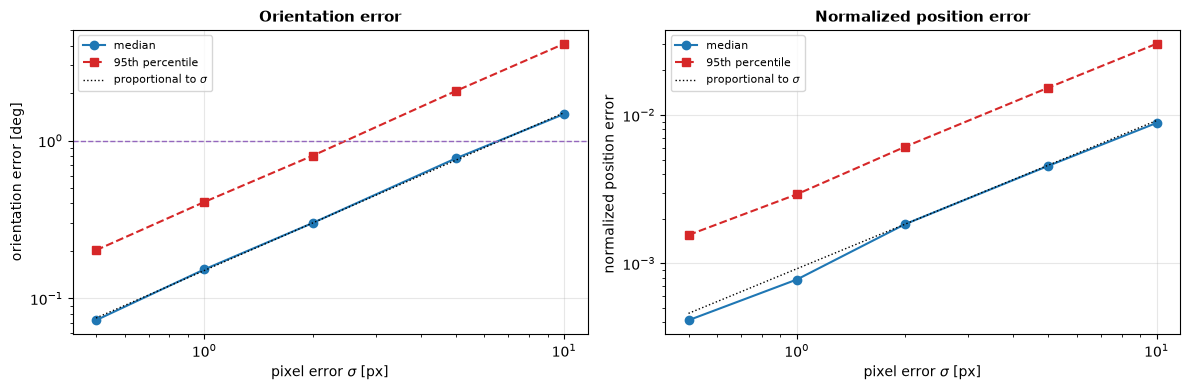

In [3]:
sigmas = np.array([0.5, 1.0, 2.0, 5.0, 10.0])
noise = {}
for sigma in sigmas:
    rows = []
    for label in sample:
        pixels = keypoints(label) + sigma * rng.standard_normal((11, 2))
        estimate = solve_pnp(camera, TANGO_KEYPOINTS, pixels, pixel_std=sigma)
        rows.append([*errors(label, estimate), speed_score(estimate.quaternion, estimate.translation,
                                                          label.quaternion, label.translation, apply_threshold=False)])
    noise[sigma] = np.array(rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for column, ax, name, unit in ((0, axes[0], "orientation error", "deg"), (1, axes[1], "normalized position error", "")):
    median = [np.median(noise[s][:, column]) for s in sigmas]
    p95 = [np.percentile(noise[s][:, column], 95) for s in sigmas]
    ax.loglog(sigmas, median, "o-", color=COL_A, label="median")
    ax.loglog(sigmas, p95, "s--", color=COL_B, label="95th percentile")
    ax.loglog(sigmas, median[2] * sigmas / 2.0, "k:", lw=1, label="proportional to $\\sigma$")
    ax.set_xlabel("pixel error $\\sigma$ [px]"); ax.set_ylabel(f"{name} {('[' + unit + ']') if unit else ''}")
    ax.set_title(name.capitalize()); ax.legend(fontsize=8)
if True:
    axes[0].axhline(1.0, color=COL_C, lw=1, ls="--")
fig.tight_layout()

print(f"{'sigma [px]':>10s} {'orientation median / p95 [deg]':>32s} {'position median / p95':>24s} {'score median':>13s}")
for sigma in sigmas:
    r = noise[sigma]
    print(f"{sigma:10.1f} {np.median(r[:, 0]):15.3f} / {np.percentile(r[:, 0], 95):6.3f} "
          f"{np.median(r[:, 1]):15.5f} / {np.percentile(r[:, 1], 95):.5f} {np.median(r[:, 2]):13.4f}")

Both errors are proportional to the pixel error over the whole range, as a first-order analysis predicts: doubling $\sigma$ doubles the median and the 95th percentile alike. With 1 px the orientation is known to 0.15 degrees on median and 0.4 degrees in 95 percent of the poses; with 10 px, to 1.5 and 4 degrees. The position error divided by the distance behaves the same way, about a thousandth per pixel of error, so the two terms of the SPEED+ score are of similar size and the score itself is about 0.004 per pixel.

For comparison, the best entries of the 2021 competition reached scores of a few hundredths on the laboratory images, around 0.06 on the sunlamp set. In terms of this table that is an error of the order of ten pixels per keypoint, which says where the difficulty lies: not in the geometry, but in finding the keypoints on real images.

## The effect of distance

The chapter predicted that both the orientation error and the position error divided by the distance grow in proportion to the distance, because the target shrinks in the image while the pixel error stays the same, and that the error along the line of sight grows faster than the error across it. The plot uses the errors at $\sigma = 2$ px, split by distance.

around 2.8 m: orientation 0.15 deg, position along the line of sight 0.2 cm, across 0.07 cm
around 9.4 m: orientation 0.51 deg, position along the line of sight 2.3 cm, across 0.28 cm


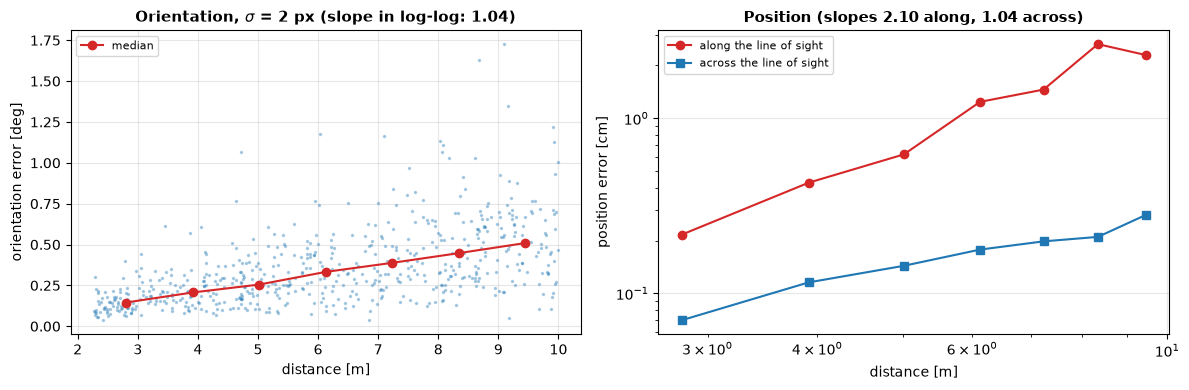

In [4]:
sigma = 2.0
rows = []
for label in sample:
    pixels = keypoints(label) + sigma * rng.standard_normal((11, 2))
    estimate = solve_pnp(camera, TANGO_KEYPOINTS, pixels, pixel_std=sigma)
    direction = label.translation / label.distance
    shift = estimate.translation - label.translation
    rows.append([*errors(label, estimate), abs(shift @ direction), np.linalg.norm(shift - (shift @ direction) * direction)])
rows = np.array(rows)

bins = np.linspace(2.25, 10.0, 8)
centers = 0.5 * (bins[1:] + bins[:-1])
index = np.digitize(distance, bins) - 1
med = lambda column: np.array([np.median(rows[index == k, column]) for k in range(len(centers))])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(distance, rows[:, 0], ".", ms=3, alpha=0.3, color=COL_A)
axes[0].plot(centers, med(0), "o-", color=COL_B, label="median")
slope = np.polyfit(np.log(centers), np.log(med(0)), 1)[0]
axes[0].set_xlabel("distance [m]"); axes[0].set_ylabel("orientation error [deg]")
axes[0].set_title(f"Orientation, $\\sigma$ = {sigma:.0f} px (slope in log-log: {slope:.2f})"); axes[0].legend(fontsize=8)

axes[1].loglog(centers, med(2) * 100, "o-", color=COL_B, label="along the line of sight")
axes[1].loglog(centers, med(3) * 100, "s-", color=COL_A, label="across the line of sight")
slope_along = np.polyfit(np.log(centers), np.log(med(2)), 1)[0]
slope_across = np.polyfit(np.log(centers), np.log(med(3)), 1)[0]
axes[1].set_xlabel("distance [m]"); axes[1].set_ylabel("position error [cm]")
axes[1].set_title(f"Position (slopes {slope_along:.2f} along, {slope_across:.2f} across)"); axes[1].legend(fontsize=8)
fig.tight_layout()

for k in (0, len(centers) - 1):
    print(f"around {centers[k]:.1f} m: orientation {med(0)[k]:.2f} deg, position along the line of sight "
          f"{med(2)[k] * 100:.1f} cm, across {med(3)[k] * 100:.2f} cm")

The measured slopes are the ones the chapter derived: the orientation error and the position error across the line of sight grow with the distance, slope 1.04 in logarithmic scale, and the error along the line of sight grows with its square, slope 2.10. At 9.4 m the distance to the target is uncertain by 2.3 cm and its lateral position by 3 mm: the camera measures directions very well and distances much less well, because a distance is inferred from how large the target looks.

The consequence for the docking is favourable. The quantities that matter most at contact, the lateral offset and the orientation, are the ones the camera measures best, and every error shrinks as the deputy closes in.

## Does the pose know how wrong it is

The refinement returns a covariance, $\sigma^2 (J^{\mathsf T}J)^{-1}$. If it is right, the error of each pose, weighted by the inverse of its covariance, is a chi-squared variable with six degrees of freedom: on average 6, and above 12.6 in only 5 percent of the cases. A navigation filter that receives the pose depends on this being true.

sigma 1 px: mean 6.10 (expected 6), above 12.6 in 6.3 % (expected 5 %)
sigma 5 px: mean 5.86 (expected 6), above 12.6 in 5.8 % (expected 5 %)


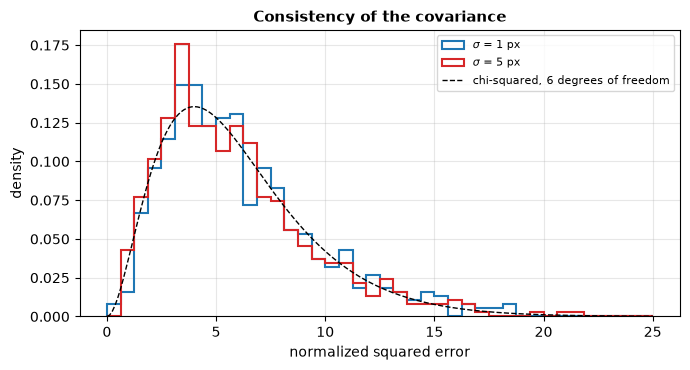

In [5]:
def error_vector(label, estimate):
    m_true = quaternion_to_rotation_matrix(label.quaternion).T
    d = quaternion_to_rotation_matrix(estimate.quaternion).T @ m_true.T
    small = 0.5 * np.array([d[2, 1] - d[1, 2], d[0, 2] - d[2, 0], d[1, 0] - d[0, 1]])
    return np.concatenate([small, estimate.translation - label.translation])


nees = {}
for sigma in (1.0, 5.0):
    values = []
    for label in sample:
        estimate = solve_pnp(camera, TANGO_KEYPOINTS, keypoints(label) + sigma * rng.standard_normal((11, 2)), sigma)
        e = error_vector(label, estimate)
        values.append(e @ np.linalg.solve(estimate.covariance, e))
    nees[sigma] = np.array(values)

fig, ax = plt.subplots(figsize=(7, 3.8))
grid = np.linspace(0, 25, 200)
from scipy.stats import chi2
for sigma, color in zip(nees, (COL_A, COL_B)):
    ax.hist(nees[sigma], bins=40, range=(0, 25), density=True, histtype="step", lw=1.5, color=color,
            label=f"$\\sigma$ = {sigma:.0f} px")
ax.plot(grid, chi2.pdf(grid, 6), "k--", lw=1, label="chi-squared, 6 degrees of freedom")
ax.set_xlabel("normalized squared error"); ax.set_ylabel("density"); ax.set_title("Consistency of the covariance")
ax.legend(fontsize=8)
fig.tight_layout()

for sigma, values in nees.items():
    print(f"sigma {sigma:.0f} px: mean {values.mean():.2f} (expected 6), above 12.6 in {(values > 12.59).mean() * 100:.1f} % (expected 5 %)")

The covariance is honest: the normalized squared error averages 6.1 and 5.9 for the two noise levels, against 6 expected, and exceeds the 95 percent bound in about 6 percent of the poses, against 5. The slight excess is the nonlinearity of the projection, which the first-order covariance ignores, and it does not grow with the noise up to 5 px. A navigation filter can take the covariance of each pose at face value, provided the pixel error it is computed with is right, which for a real detector will have to be measured.

## Fewer keypoints

A detector does not always find every keypoint: some are outside the image, some are hidden behind the body, some are found with too little confidence to be used. The test repeats the recovery at $\sigma = 2$ px with subsets of the eleven keypoints, chosen at random, down to the six that the linear estimate needs.

 6 keypoints: median 0.47 deg, 95th percentile 1.56 deg, above 5 deg in 1.7 % of the poses
 7 keypoints: median 0.38 deg, 95th percentile 1.17 deg, above 5 deg in 0.0 % of the poses
 8 keypoints: median 0.37 deg, 95th percentile 1.01 deg, above 5 deg in 0.0 % of the poses
 9 keypoints: median 0.32 deg, 95th percentile 0.92 deg, above 5 deg in 0.0 % of the poses
10 keypoints: median 0.33 deg, 95th percentile 0.80 deg, above 5 deg in 0.0 % of the poses
11 keypoints: median 0.30 deg, 95th percentile 0.86 deg, above 5 deg in 0.0 % of the poses


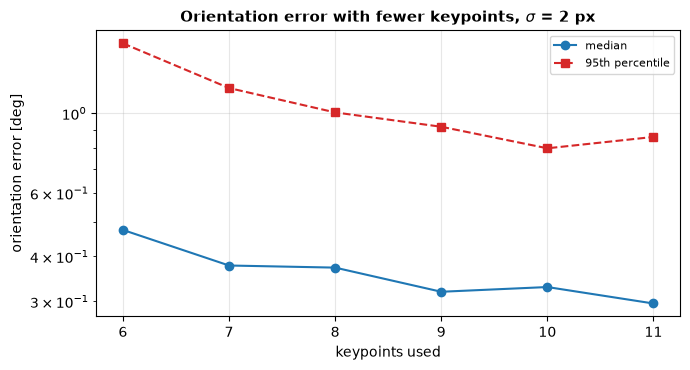

In [6]:
counts = [6, 7, 8, 9, 10, 11]
subset = {}
for n in counts:
    values = []
    for label in sample[:300]:
        chosen = rng.choice(11, n, replace=False)
        pixels = keypoints(label)[chosen] + 2.0 * rng.standard_normal((n, 2))
        try:
            values.append(errors(label, solve_pnp(camera, TANGO_KEYPOINTS[chosen], pixels))[0])
        except (np.linalg.LinAlgError, ValueError):
            values.append(np.nan)
    subset[n] = np.array(values)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(counts, [np.nanmedian(subset[n]) for n in counts], "o-", color=COL_A, label="median")
ax.plot(counts, [np.nanpercentile(subset[n], 95) for n in counts], "s--", color=COL_B, label="95th percentile")
ax.set_yscale("log")
ax.set_xlabel("keypoints used"); ax.set_ylabel("orientation error [deg]")
ax.set_title("Orientation error with fewer keypoints, $\\sigma$ = 2 px"); ax.legend(fontsize=8)
fig.tight_layout()

for n in counts:
    print(f"{n:2d} keypoints: median {np.nanmedian(subset[n]):.2f} deg, 95th percentile {np.nanpercentile(subset[n], 95):.2f} deg, "
          f"above 5 deg in {(subset[n] > 5).mean() * 100:.1f} % of the poses")

Losing keypoints costs little as long as enough remain. Going from eleven to eight raises the 95th percentile of the orientation error from 0.86 to 1.0 degrees; with six, the minimum, it rises to 1.6 degrees and a few poses, 1.7 percent, come out wrong by more than 5 degrees, because six points chosen at random can lie almost on one plane or on one side of the body, which leaves the pose poorly determined. A detector that finds at least eight of the eleven keypoints loses almost nothing; one that finds only six needs a check on the geometry of the points it found.

## A keypoint in the wrong place

The typical failure of a detector is not a small error on every point but a large error on one: a corner of the panel confused with another, an antenna tip found on its own reflection. The test moves one keypoint by 30 to 150 pixels in a random direction, on top of an error of 1 px on all, and compares the plain solution with the RANSAC loop, which looks for the largest set of keypoints that agree with one pose.

all keypoints: median 3.08 deg, above 1 deg in 90 % of the poses
RANSAC: median 0.16 deg, above 1 deg in 0 %; wrong keypoint rejected in 100 % of the poses


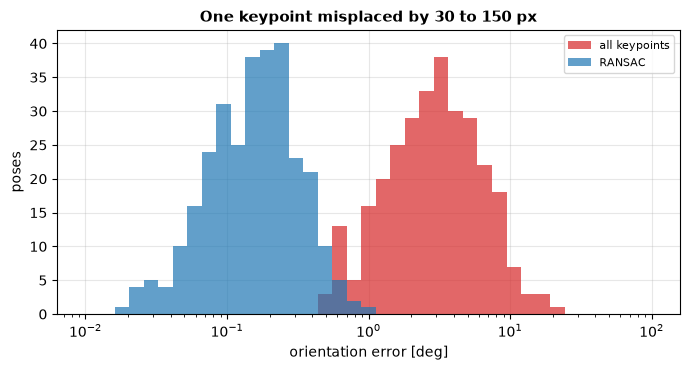

In [7]:
plain, robust, rejected = [], [], []
for label in sample[:300]:
    pixels = keypoints(label) + 1.0 * rng.standard_normal((11, 2))
    wrong = rng.integers(11)
    angle = rng.uniform(0, 2 * np.pi)
    pixels[wrong] += rng.uniform(30, 150) * np.array([np.cos(angle), np.sin(angle)])
    plain.append(errors(label, solve_pnp(camera, TANGO_KEYPOINTS, pixels))[0])
    estimate = ransac_pnp(camera, TANGO_KEYPOINTS, pixels, threshold=8.0, rng=rng)
    robust.append(errors(label, estimate)[0])
    rejected.append(not estimate.inliers[wrong])
plain, robust = np.array(plain), np.array(robust)

fig, ax = plt.subplots(figsize=(7, 3.8))
bins = np.logspace(-2, 2, 40)
ax.hist(plain, bins=bins, alpha=0.7, color=COL_B, label="all keypoints")
ax.hist(robust, bins=bins, alpha=0.7, color=COL_A, label="RANSAC")
ax.set_xscale("log"); ax.set_xlabel("orientation error [deg]"); ax.set_ylabel("poses")
ax.set_title("One keypoint misplaced by 30 to 150 px"); ax.legend(fontsize=8)
fig.tight_layout()

print(f"all keypoints: median {np.median(plain):.2f} deg, above 1 deg in {(plain > 1).mean() * 100:.0f} % of the poses")
print(f"RANSAC: median {np.median(robust):.2f} deg, above 1 deg in {(robust > 1).mean() * 100:.0f} %; "
      f"wrong keypoint rejected in {np.mean(rejected) * 100:.0f} % of the poses")

One misplaced keypoint is enough to ruin the plain solution: the median orientation error grows twentyfold, to 3 degrees, and 90 percent of the poses are wrong by more than a degree, because the least squares fit spreads the error of the wrong point over the whole pose. The RANSAC loop finds and rejects the wrong keypoint in every case and returns a pose as good as if it had never been there. Any pose estimation chain fed by a detector needs this step, and the residual of the accepted points is also the first indicator that a pose should not be trusted.

## What the detector has to achieve

The requirement of the problem chapter is an orientation known to about 1 degree in the last metres, with a margin. Since the error grows in proportion to both the pixel error and the distance, the largest pixel error that meets a given orientation accuracy at a given distance follows from the measured errors by scaling. The table gives it for the 95th percentile of the orientation error, at the far end of the range of SPEED+ and at the middle.

In [8]:
reference = noise[2.0][:, 0]
for limit in (1.0, 0.5):
    for low, high in ((5.0, 7.0), (8.5, 10.0)):
        band = (distance >= low) & (distance < high)
        p95 = np.percentile(reference[band], 95)
        print(f"orientation within {limit:.1f} deg for 95 % of the poses between {low:.1f} and {high:.0f} m: "
              f"pixel error up to {2.0 * limit / p95:.1f} px")

orientation within 1.0 deg for 95 % of the poses between 5.0 and 7 m: pixel error up to 3.3 px
orientation within 1.0 deg for 95 % of the poses between 8.5 and 10 m: pixel error up to 1.9 px
orientation within 0.5 deg for 95 % of the poses between 5.0 and 7 m: pixel error up to 1.6 px
orientation within 0.5 deg for 95 % of the poses between 8.5 and 10 m: pixel error up to 0.9 px


To keep the orientation within 1 degree in 95 percent of the cases at 8.5 to 10 m, the keypoints must be found within about 2 px; at 5 to 7 m, within about 3 px. Closer in the tolerance grows further. These are the targets for the keypoint detector of the next part. They are demanding for a network trained on rendered images and applied to real ones, and comfortable for one applied to images like those it was trained on.

## Summary

`solve_pnp` recovers the pose from the pixels of the keypoints in three stages, a linear estimate, a refinement on the reprojection error and the covariance from the Jacobian, and `ransac_pnp` adds the rejection of grossly wrong keypoints. On the geometry of SPEED+ the chain is exact without noise, its error is proportional to the pixel error, the orientation and the lateral position degrade linearly with the distance and the depth quadratically, and its covariance is consistent with the actual errors.

The number to carry forward is the requirement on the detector: about 2 px per keypoint for an orientation within 1 degree at 10 m, and the ability to signal or survive a keypoint that is completely wrong. The next part builds the detector and measures how close it comes on rendered and on laboratory images.